<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/07_Regression_Departures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Regression Task: Departures
1. Baseline
2. Linear Regression 1
3. Decision Tree 1

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Read the saved feature set
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"
else:
    DATA = "../data"
PROCESSED = f"{DATA}/processed"
TABLE = f"{PROCESSED}/regression_station_hour_may_oct.parquet"

TARGET = "departures"

# feature groups from report Part 1.1
CATEGORICAL = ["hour_of_day", "day_of_week", "month", "station_id"]
NUMERIC = ["year", "weekend_or_holiday", "temp_c", "precip_mm", "prec_mm_prev_hr", "new_station"]

# read the table and split it using the split column from Part 1.3.6
data = pd.read_parquet(TABLE)
train = data[data["split"] == "train"].reset_index(drop=True)
val = data[data["split"] == "val"].reset_index(drop=True)
test = data[data["split"] == "test"].reset_index(drop=True)   # not looked at until Section 6
del data

print("Training rows:  ", f"{len(train):,}", " stations:", train["station_id"].nunique())
print("Validation rows:", f"{len(val):,}", " stations:", val["station_id"].nunique())

unseen = set(val["station_id"]) - set(train["station_id"])
print("Validation stations that are not in training:", len(unseen))
print(f"Average {TARGET} per station-hour in training: {train[TARGET].mean():.3f}")
print(f"Share of training rows with zero {TARGET}: {(train[TARGET] == 0).mean():.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training rows:   3,660,096  stations: 826
Validation rows: 3,078,048  stations: 863
Validation stations that are not in training: 58
Average departures per station-hour in training: 1.305
Share of training rows with zero departures: 0.572


In [10]:
# Helper: MAE and RMSE for one set of predictions
def evaluate(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

# we collect validation predictions of every model here, one column per model
val_results = pd.DataFrame()
val_results["station_id"] = val["station_id"]
val_results["hour_ts"] = val["hour_ts"]
val_results["actual"] = val[TARGET]

# and the scores here
scores = {}

1. Baseline (average departure for the same station, hour of day, day of week)

In [11]:
def baseline_predict(fit_data, apply_data):
    # average by station, hour and weekday from the fitting rows
    averages = fit_data.groupby(["station_id", "hour_of_day", "day_of_week"])[TARGET].mean()
    averages = averages.rename("baseline").reset_index()

    # fallback average by hour and weekday only, for stations with no history
    fallback = fit_data.groupby(["hour_of_day", "day_of_week"])[TARGET].mean()
    fallback = fallback.rename("fallback").reset_index()

    # look up both for every row we want to predict
    lookup = apply_data[["station_id", "hour_of_day", "day_of_week"]]
    lookup = lookup.merge(averages, on=["station_id", "hour_of_day", "day_of_week"], how="left")
    lookup = lookup.merge(fallback, on=["hour_of_day", "day_of_week"], how="left")

    # use the station average where it exists, otherwise the fallback
    prediction = lookup["baseline"].fillna(lookup["fallback"])
    return prediction.to_numpy()

val_results["baseline"] = baseline_predict(train, val)
scores["Baseline"] = evaluate(val_results["actual"], val_results["baseline"])
print("Baseline on validation: MAE = %.4f, RMSE = %.4f" % scores["Baseline"])

Baseline on validation: MAE = 0.9323, RMSE = 1.7949


2. Linear Regression

In [12]:
# one-hot encode the categorical columns, pass the numeric columns through unchanged
encoder = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("numeric", "passthrough", NUMERIC),
])

# fit the encoder and the model on the training rows
X_train = encoder.fit_transform(train[CATEGORICAL + NUMERIC])
y_train = train[TARGET]
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# predict the validation rows
X_val = encoder.transform(val[CATEGORICAL + NUMERIC])
linear_raw = linear_model.predict(X_val)

share_negative = (linear_raw < 0).mean()
print(f"Percentage of validation predictions below zero: {share_negative:.1%}  (set to 0 before scoring)")

val_results["linear"] = np.clip(linear_raw, 0, None)
scores["Linear regression"] = evaluate(val_results["actual"], val_results["linear"])
print("Linear regression on validation: MAE = %.4f, RMSE = %.4f" % scores["Linear regression"])

# the coefficients of the numeric features are easy to read: change in the target per one unit of the feature
numeric_coefficients = pd.Series(linear_model.coef_[-len(NUMERIC):], index=NUMERIC)
print("\nCoefficients of the numeric features:")
print(numeric_coefficients.round(4).to_string())

Percentage of validation predictions below zero: 19.8%  (set to 0 before scoring)
Linear regression on validation: MAE = 1.1860, RMSE = 2.1668

Coefficients of the numeric features:
year                  0.0147
weekend_or_holiday   -0.3989
temp_c                0.0375
precip_mm            -0.0992
prec_mm_prev_hr      -0.0676
new_station          -0.4180


2. Decision Trees

In [13]:
# replace station_id by the station's training average
def station_average(fit_data, apply_data):
    averages = fit_data.groupby("station_id")[TARGET].mean().rename("station_avg").reset_index()
    lookup = apply_data[["station_id"]].merge(averages, on="station_id", how="left")
    overall = fit_data[TARGET].mean()
    return lookup["station_avg"].fillna(overall).to_numpy()

TREE_FEATURES = ["station_avg", "hour_of_day", "day_of_week", "month"] + NUMERIC

train_tree = train[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
train_tree["station_avg"] = station_average(train, train)
train_tree = train_tree[TREE_FEATURES]

val_tree = val[["hour_of_day", "day_of_week", "month"] + NUMERIC].copy()
val_tree["station_avg"] = station_average(train, val)
val_tree = val_tree[TREE_FEATURES]

# try several depths
depths = [6, 9, 12, 15, 20]
depth_rows = []
tree_predictions = {}
for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=100, random_state=42)
    tree.fit(train_tree, train[TARGET])
    prediction = tree.predict(val_tree)
    tree_predictions[depth] = prediction

    train_mae = mean_absolute_error(train[TARGET], tree.predict(train_tree))
    val_mae, val_rmse = evaluate(val[TARGET], prediction)
    depth_rows.append({"max_depth": depth, "train MAE": train_mae, "val MAE": val_mae, "val RMSE": val_rmse})

depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(4).to_string(index=False))

# keep the depth with the lowest validation MAE
best_row = depth_table.loc[depth_table["val MAE"].idxmin()]
best_depth = int(best_row["max_depth"])
print(f"\nChosen depth: {best_depth}")

val_results["tree"] = tree_predictions[best_depth]
tree_name = f"Decision tree (depth {best_depth})"
scores[tree_name] = evaluate(val_results["actual"], val_results["tree"])
print(tree_name + " on validation: MAE = %.4f, RMSE = %.4f" % scores[tree_name])

# which features the chosen tree uses most
best_tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=100, random_state=42)
best_tree.fit(train_tree, train[TARGET])
importance = pd.Series(best_tree.feature_importances_, index=TREE_FEATURES).sort_values(ascending=False)
print("\nFeature importance:")
print(importance.round(3).to_string())

 max_depth  train MAE  val MAE  val RMSE
         6     0.9911   1.0371    2.0495
         9     0.9457   1.0066    1.9754
        12     0.9066   0.9767    1.8939
        15     0.8821   0.9671    1.8586
        20     0.8573   0.9583    1.8328

Chosen depth: 20
Decision tree (depth 20) on validation: MAE = 0.9583, RMSE = 1.8328

Feature importance:
station_avg           0.527
hour_of_day           0.387
temp_c                0.030
weekend_or_holiday    0.028
day_of_week           0.012
precip_mm             0.009
month                 0.006
prec_mm_prev_hr       0.001
year                  0.001
new_station           0.000


### Comparison of models

                             MAE    RMSE  change vs baseline MAE
Baseline                  0.9323  1.7949                  0.0000
Linear regression         1.1860  2.1668                 27.2052
Decision tree (depth 20)  0.9583  1.8328                  2.7830


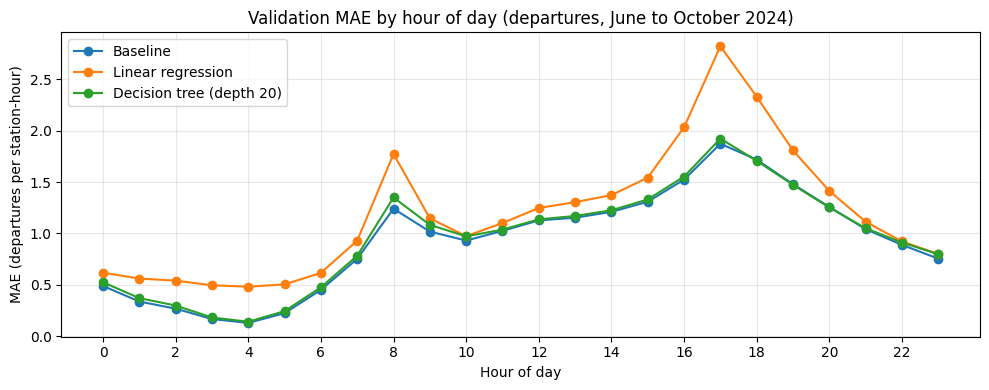

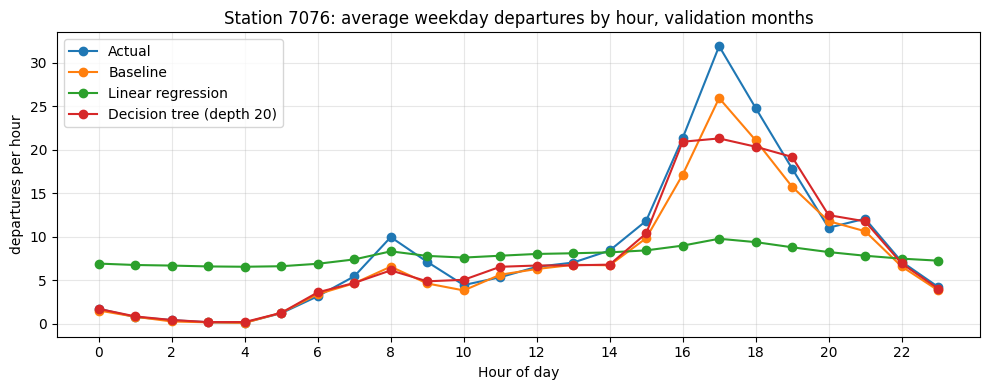

In [14]:
# table of scores
comparison = pd.DataFrame(scores, index=["MAE", "RMSE"]).T
baseline_mae = comparison.loc["Baseline", "MAE"]
comparison["change vs baseline MAE"] = (comparison["MAE"] / baseline_mae - 1) * 100
comparison = comparison.round(4)
print(comparison.to_string())

# which column in val_results belongs to which model name
model_columns = {"Baseline": "baseline", "Linear regression": "linear", tree_name: "tree"}

# MAE by hour of day on validation, one line per model
by_hour = pd.DataFrame(index=range(24))
for name, column in model_columns.items():
    abs_error = (val_results[column] - val_results["actual"]).abs()
    by_hour[name] = abs_error.groupby(val["hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
by_hour.plot(ax=ax, marker="o")
ax.set_title(f"Validation MAE by hour of day ({TARGET}, June to October 2024)")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"MAE ({TARGET} per station-hour)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# the busiest station in training: average weekday profile, actual vs predicted
busiest_station = train.groupby("station_id")[TARGET].sum().idxmax()
is_busiest_weekday = (val["station_id"] == busiest_station) & (val["weekend_or_holiday"] == 0)

profile = pd.DataFrame(index=range(24))
profile["Actual"] = val_results.loc[is_busiest_weekday, "actual"].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()
for name, column in model_columns.items():
    profile[name] = val_results.loc[is_busiest_weekday, column].groupby(val.loc[is_busiest_weekday, "hour_of_day"]).mean()

fig, ax = plt.subplots(figsize=(10, 4))
profile.plot(ax=ax, marker="o")
ax.set_title(f"Station {busiest_station}: average weekday {TARGET} by hour, validation months")
ax.set_xlabel("Hour of day")
ax.set_ylabel(f"{TARGET} per hour")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()